# Fase 0 · Etapa 0.5 — Graus de liberdade e condições de contorno (C3, I12)

> **Base de dados usada:** nenhum dado experimental. Só o **modelo legado** (matrizes,
> `contorno`) e a **solução analítica de Euler–Bernoulli** (raízes βL tabeladas em
> Blevins). Nenhuma base externa.

**Pergunta.** A força e a resposta do modelo legado estão no ponto e na direção onde
estavam o martelo e o acelerômetro? E a malha de 5 elementos é fina o bastante?

**Convenção do legado (lida em `matrixes()`):** cada nó tem 6 GL na ordem
`[u, v, v', w, w', θ]` — axial, flexão no plano (eixo forte), sua rotação, flexão fora
do plano (eixo fraco, a direção do martelo), sua rotação, torção.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.linalg as sla

from dampid.analytic import beam
from dampid.audit import legacy_harness as lh
from dampid.audit import reference as ref

B = lh.load_legacy()
N = 6
rows = []
for cc in ["engastado_livre", "engastado_engastado"]:
    _, free, nfree, pr = B.contorno(cc, 6, N)
    f_idx = nfree - 3 if cc == "engastado_livre" else nfree // 2 - 3     # como em calculo_numerico_modal
    L = B.material_prop("aluminio")[3]
    for papel, k in [("força", f_idx), ("resposta", pr)]:
        node, x, dof = ref.describe_legacy_dof(free[k], N, L)
        rows.append({"CC": cc, "papel": papel, "índice livre": k, "GL global": free[k],
                     "nó": node, "x [mm]": round(1e3 * x, 1), "x/L": round(x / L, 2), "GL": dof})
print(pd.DataFrame(rows).to_string(index=False))

                 CC    papel  índice livre  GL global  nó  x [mm]  x/L GL
    engastado_livre    força            27         33   5   271.0  1.0  w
    engastado_livre resposta            28         34   5   271.0  1.0 w'
engastado_engastado    força             9         15   2   108.4  0.4  w
engastado_engastado resposta             9         15   2   108.4  0.4  w


**Confirmado (C3).** No engaste-livre a força entra em `w` do nó da ponta (certo), mas a
resposta é lida em `w'` — a **rotação** da ponta. A "aceleração" numérica comparada com
o acelerômetro é uma aceleração **angular** [rad/s²].

**Confirmado (I12).** No engaste-engaste, com 6 nós, não existe nó no centro (x/L = 0,5):
força e resposta caem no nó 2, em x = 0,4 L. A direção (`w`) está certa; a posição não.

## Efeito na FRF (C3)
A mesma estrutura do legado (K, M de 6 nós), com amortecimento modal **correto** de 0,5 %
para isolar só o efeito do GL: FRF de acelerância da força na ponta para (a) `w` da
ponta (o que o acelerômetro mede) e (b) `w'` da ponta (o que o legado lê).

modo 1 (36 Hz): |A_w'|/|A_w| =   5.08 1/m  | analítico φ'(L)/φ(L) =   5.08 1/m
modo 2 (223 Hz): |A_w'|/|A_w| =  17.64 1/m  | analítico φ'(L)/φ(L) =  17.64 1/m


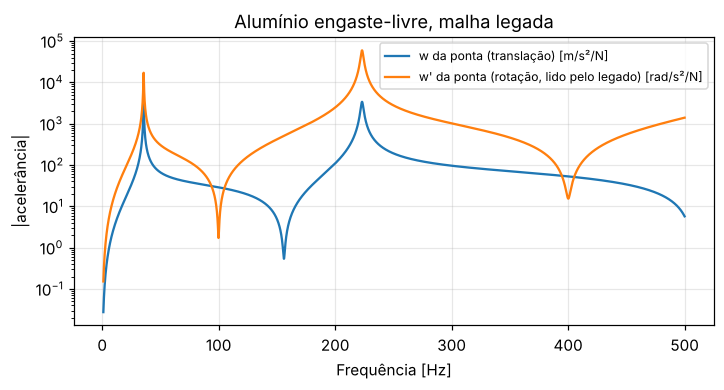

In [2]:
K, M = lh.assemble_legacy(B, "aluminio", N)
_, free, nfree, pr = B.contorno("engastado_livre", 6, N)
Kf, Mf = K[np.ix_(free, free)], M[np.ix_(free, free)]
w2, Phi = sla.eigh(Kf, Mf)
C = ref.modal_damping_matrix(Mf, Phi, np.sqrt(w2), np.full(len(w2), 0.005))
f = np.linspace(1, 500, 4000)
F = np.zeros(nfree); F[nfree - 3] = 1.0
U = np.array([np.linalg.solve(Kf - (2 * np.pi * fi) ** 2 * Mf + 2j * np.pi * fi * C, F) for fi in f])
A_w = -(2 * np.pi * f) ** 2 * U[:, nfree - 3]
A_wp = -(2 * np.pi * f) ** 2 * U[:, pr]
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.semilogy(f, np.abs(A_w), label="w da ponta (translação) [m/s²/N]")
ax.semilogy(f, np.abs(A_wp), label="w' da ponta (rotação, lido pelo legado) [rad/s²/N]")
ax.set(xlabel="Frequência [Hz]", ylabel="|acelerância|", title="Alumínio engaste-livre, malha legada")
ax.grid(alpha=0.3); ax.legend(fontsize=8)
# razão inclinação/deslocamento na ponta, analítica (Euler–Bernoulli em balanço)
def tip_slope_ratio(beta_l, L):
    s = (np.cosh(beta_l) + np.cos(beta_l)) / (np.sinh(beta_l) + np.sin(beta_l))
    phi = np.cosh(beta_l) - np.cos(beta_l) - s * (np.sinh(beta_l) - np.sin(beta_l))
    dphi = (np.sinh(beta_l) + np.sin(beta_l) - s * (np.cosh(beta_l) - np.cos(beta_l))) * beta_l / L
    return dphi / phi
L_al = B.material_prop("aluminio")[3]
for r, bl in enumerate(beam.bending_roots("clamped-free", 2), start=1):
    fr = np.sqrt(w2) / 2 / np.pi
    fn = [x for x in fr if abs(x - (bl / 1.8751) ** 2 * fr[0]) / fr[0] < 0.2 * r][0]
    i = np.argmin(np.abs(f - fn))
    print(f"modo {r} ({f[i]:.0f} Hz): |A_w'|/|A_w| = {np.abs(A_wp[i]) / np.abs(A_w[i]):6.2f} 1/m"
          f"  | analítico φ'(L)/φ(L) = {abs(tip_slope_ratio(bl, L_al)):6.2f} 1/m")

Os picos aparecem nas mesmas frequências (é a mesma estrutura), mas a **amplitude** e a
**forma** entre picos (antirressonâncias) mudam: a razão rotação/translação é diferente
em cada modo (≈5 m⁻¹ no 1º e ≈17,6 m⁻¹ no 2º, iguais à inclinação/deslocamento analítica
da ponta) — um fator de escala diferente por modo, que nenhuma constante corrige. Uma métrica sensível a amplitude (ou a antirressonâncias) compara
grandezas diferentes; as invariantes à escala (RVAC/TSAC) só disfarçam parte do problema.

## Convergência de malha (I12)
Frequências dos modos de flexão fora do plano (`w`) do modelo legado em balanço contra a
solução analítica de Euler–Bernoulli, f_n = (β_nL)²/(2πL²)·√(EI/ρA), com as mesmas
propriedades. Para isolar o efeito da malha, o termo de massa extra do legado (I4) é
desprezível aqui (ver notebook 05).

In [3]:
E, nu, rho, L, a, b, Iy, Iz, A, G, J = B.material_prop("aluminio")
f_an = beam.bending_frequencies_hz(E, Iy, rho, A, L, "clamped-free", 5)


def w_bending_freqs(n_points):
    K, M = lh.assemble_legacy(B, "aluminio", n_points)
    _, free, _, _ = B.contorno("engastado_livre", 6, n_points)
    Kf, Mf = K[np.ix_(free, free)], M[np.ix_(free, free)]
    w2, V = sla.eigh(Kf, Mf)
    dof_type = np.array(free) % 6
    share_w = np.sum(V[(dof_type == 3) | (dof_type == 4)] ** 2, axis=0) / np.sum(V**2, axis=0)
    return np.sqrt(w2[share_w > 0.9]) / 2 / np.pi


res = []
for n in (3, 4, 6, 11, 21, 41):
    fw = w_bending_freqs(n)[:5]
    res.append({"nós": n, **{f"modo {i + 1} erro %": round(100 * (fw[i] / f_an[i] - 1), 3) if i < len(fw) else None
                            for i in range(5)}})
print("Analítico [Hz]:", np.round(f_an, 1))
print(pd.DataFrame(res).to_string(index=False))

Analítico [Hz]: [  35.6  223.   624.3 1223.4 2022.3]
 nós  modo 1 erro %  modo 2 erro %  modo 3 erro %  modo 4 erro %  modo 5 erro %
   3          0.048          0.849         21.816         80.426            NaN
   4          0.010          0.328          1.246         16.351         32.465
   6          0.001          0.050          0.359          1.173          1.581
  11          0.000          0.003          0.025          0.095          0.252
  21         -0.000          0.000          0.002          0.006          0.017
  41         -0.000         -0.000          0.000          0.000          0.001


**Leitura (melhor do que a hipótese herdada).** O elemento cúbico de Hermite converge
muito rápido: com 6 nós (legado) o erro é 0,001 % e 0,05 % nos dois modos de flexão do
alumínio em balanço que caem abaixo de 500 Hz, e chega a ~1 % só no 4º modo. Para os
metais em balanço, **a malha não é o problema**. Ela pesa mais para o acrílico (até o
4º modo cai na banda) e para o livre-livre, e não houve estudo de convergência que
mostrasse isso. O que o I12 tem de grave é a **posição**: com N par não existe nó no
centro, e força/resposta foram parar em 0,4 L. A malha nova precisa ter nós nos pontos
de força e de medição (ou interpolar, como previsto na Fase 4).

## Resumo da etapa
| Item | Status | Evidência |
|---|---|---|
| C3 | **confirmado** | resposta em `w'` (rotação) do nó da ponta; força em `w` |
| I12 | **parcial** | posição **confirmada** (engaste-engaste em x = 0,4 L); malha de 5 elementos é suficiente para metais em balanço (erro ≤ 0,05 % na banda), ~1 % no 4º modo |